# Interpreting single reads with PRISM

PRISM (per-read in-silico mutagenesis) asks how each DNA substitution changes the model's
likelihood of one observed read. Reads from the same region can tell different stories: a
read with a bound transcription factor and a read with a nucleosome over the same motif
respond to that motif in opposite directions, which an average accessibility profile
blurs together.

This notebook runs PRISM on two reads of one ONT mESC region, then compares it with profile
ISM, which explains the predicted average profile instead. Everything it needs comes with
the repository, apart from the model, which is downloaded from the Hugging Face Hub. It
needs a GPU: scoring one read takes a few seconds there.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from smf_net.data import densify_smf
from smf_net.evaluation.ism import profile_ism
from smf_net.evaluation.ism_plotting import plot_profile_ism
from smf_net.evaluation.prism import prism
from smf_net.evaluation.prism_plotting import plot_prism
from smf_net.model import load_model

## Load the model

In [2]:
model = load_model("kundajelab/smfnet-ont-mesc").cuda()

## Load the region and its reads

`examples/data/` holds one validation region of the ONT mESC data: the 2048 bp DNA the model
reads and the 128 observed reads in sparse form, with one column per call site. The model
predicts the central 1024 bp. Here SMF 1 means occupied (methylase-protected) and 0
accessible; `densify_smf` places the calls on the full DNA window, with -1 where a read has
no call.

In [3]:
region = np.load("data/ont_mesc_chr16_50073256-50075370.npz")
region_id = str(region["region_id"])
dna = torch.from_numpy(region["dna"])
reads = densify_smf(
    torch.from_numpy(region["smf"]),
    torch.from_numpy(region["positions"]),
    region_len=len(dna),
).long()
print(region_id, tuple(dna.shape), tuple(reads.shape))

chr16:50073256-50075370 (2048,) (128, 2048)


## Score two reads

We compare reads 91 and 92 and mutate the 100 bp starting at input position 800, which holds
a motif. Read 91 is accessible on either side of a short protected stretch over the motif,
a transcription factor footprint; read 92 is protected throughout, as under a nucleosome.

For every substitution, PRISM scores the read's log-likelihood along several random
unmasking orders of the diffusion sampler (`n_unmasking_orders`, 8 by default) and averages
the change from the reference sequence.

In [4]:
mutation_start = 800
length = 100
results = {
    read: prism(
        model,
        reads[read],
        dna,
        mutation_start=mutation_start,
        length=length,
        batch_size=64,
    )
    for read in (91, 92)
}

Each figure shows the read over the mutated window, then the reference bases weighted by
how much mutating them lowers (positive influence) or raises (negative influence) the read's
log-likelihood, and finally the change for every substitution.

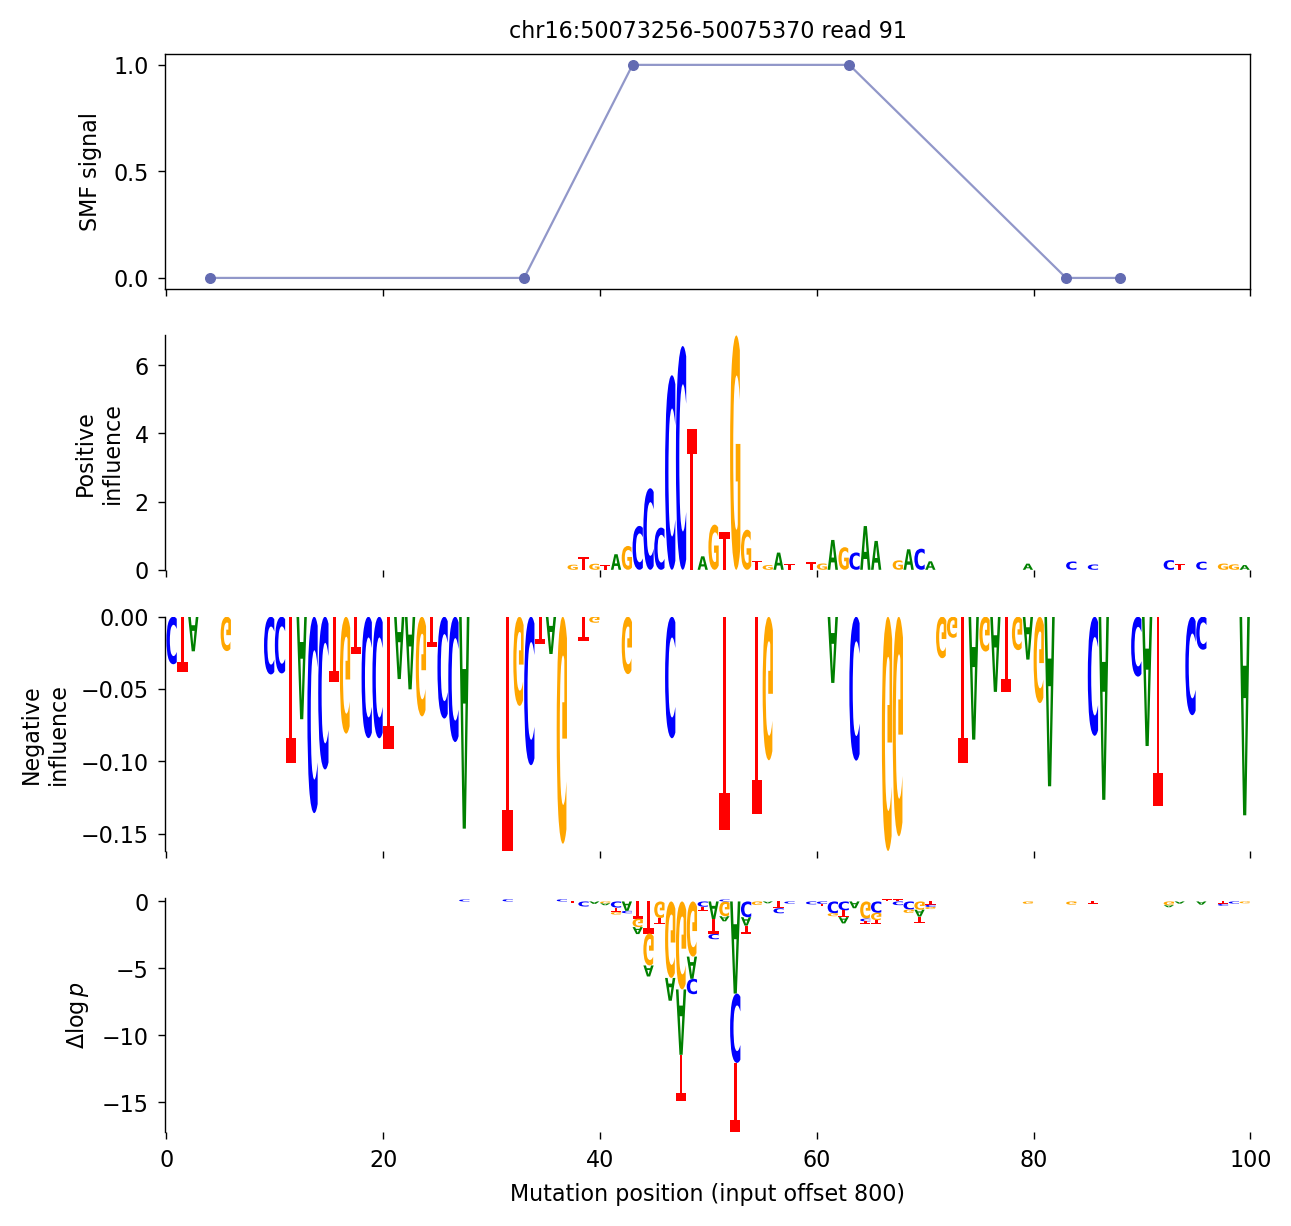

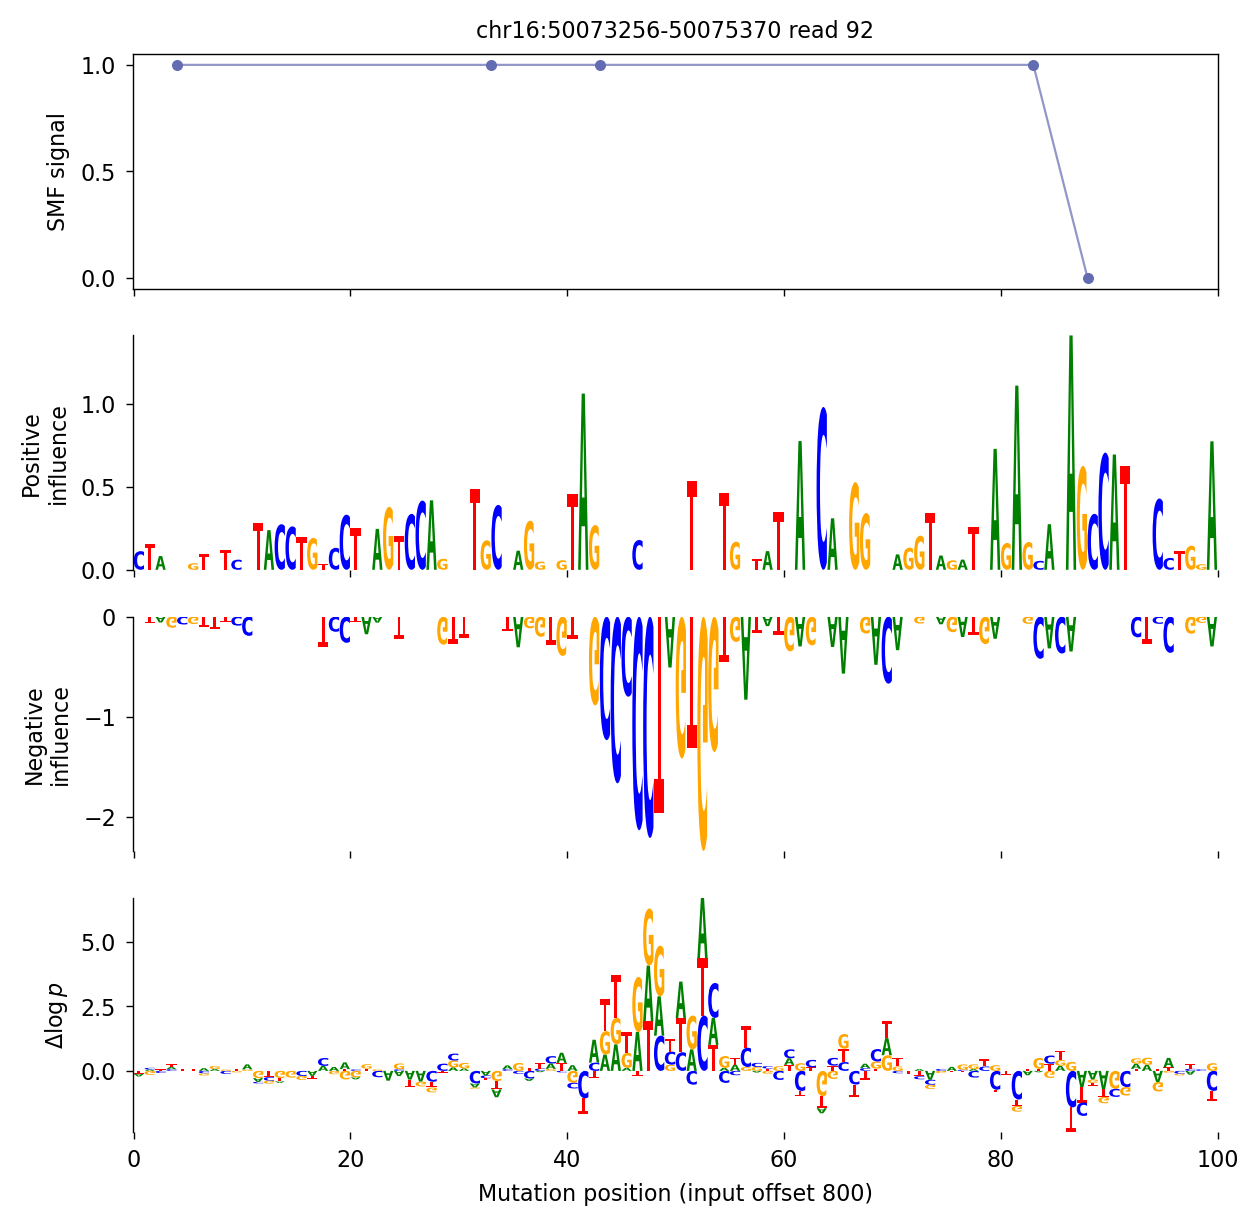

In [5]:
for read, result in results.items():
    figure = plot_prism(result, f"{region_id} read {read}")
    plt.show()

The motif makes the bound read 91 more likely: mutating it lowers that read's likelihood,
so it shows up as positive influence. For the nucleosomal read 92 the same motif makes the
read less likely, and mutating it raises the likelihood. In other words, the model has
learned that the motif favors a bound factor over a nucleosome at this site.

## Compare with profile ISM

Profile ISM mutates the same window and measures the change in the predicted profile (logits
of the average SMF) at every output position, without conditioning on any read. With
`scaled=True`, effects are weighted by a smoothed version of the predicted accessibility,
emphasizing broadly accessible stretches such as transcription factor binding sites.

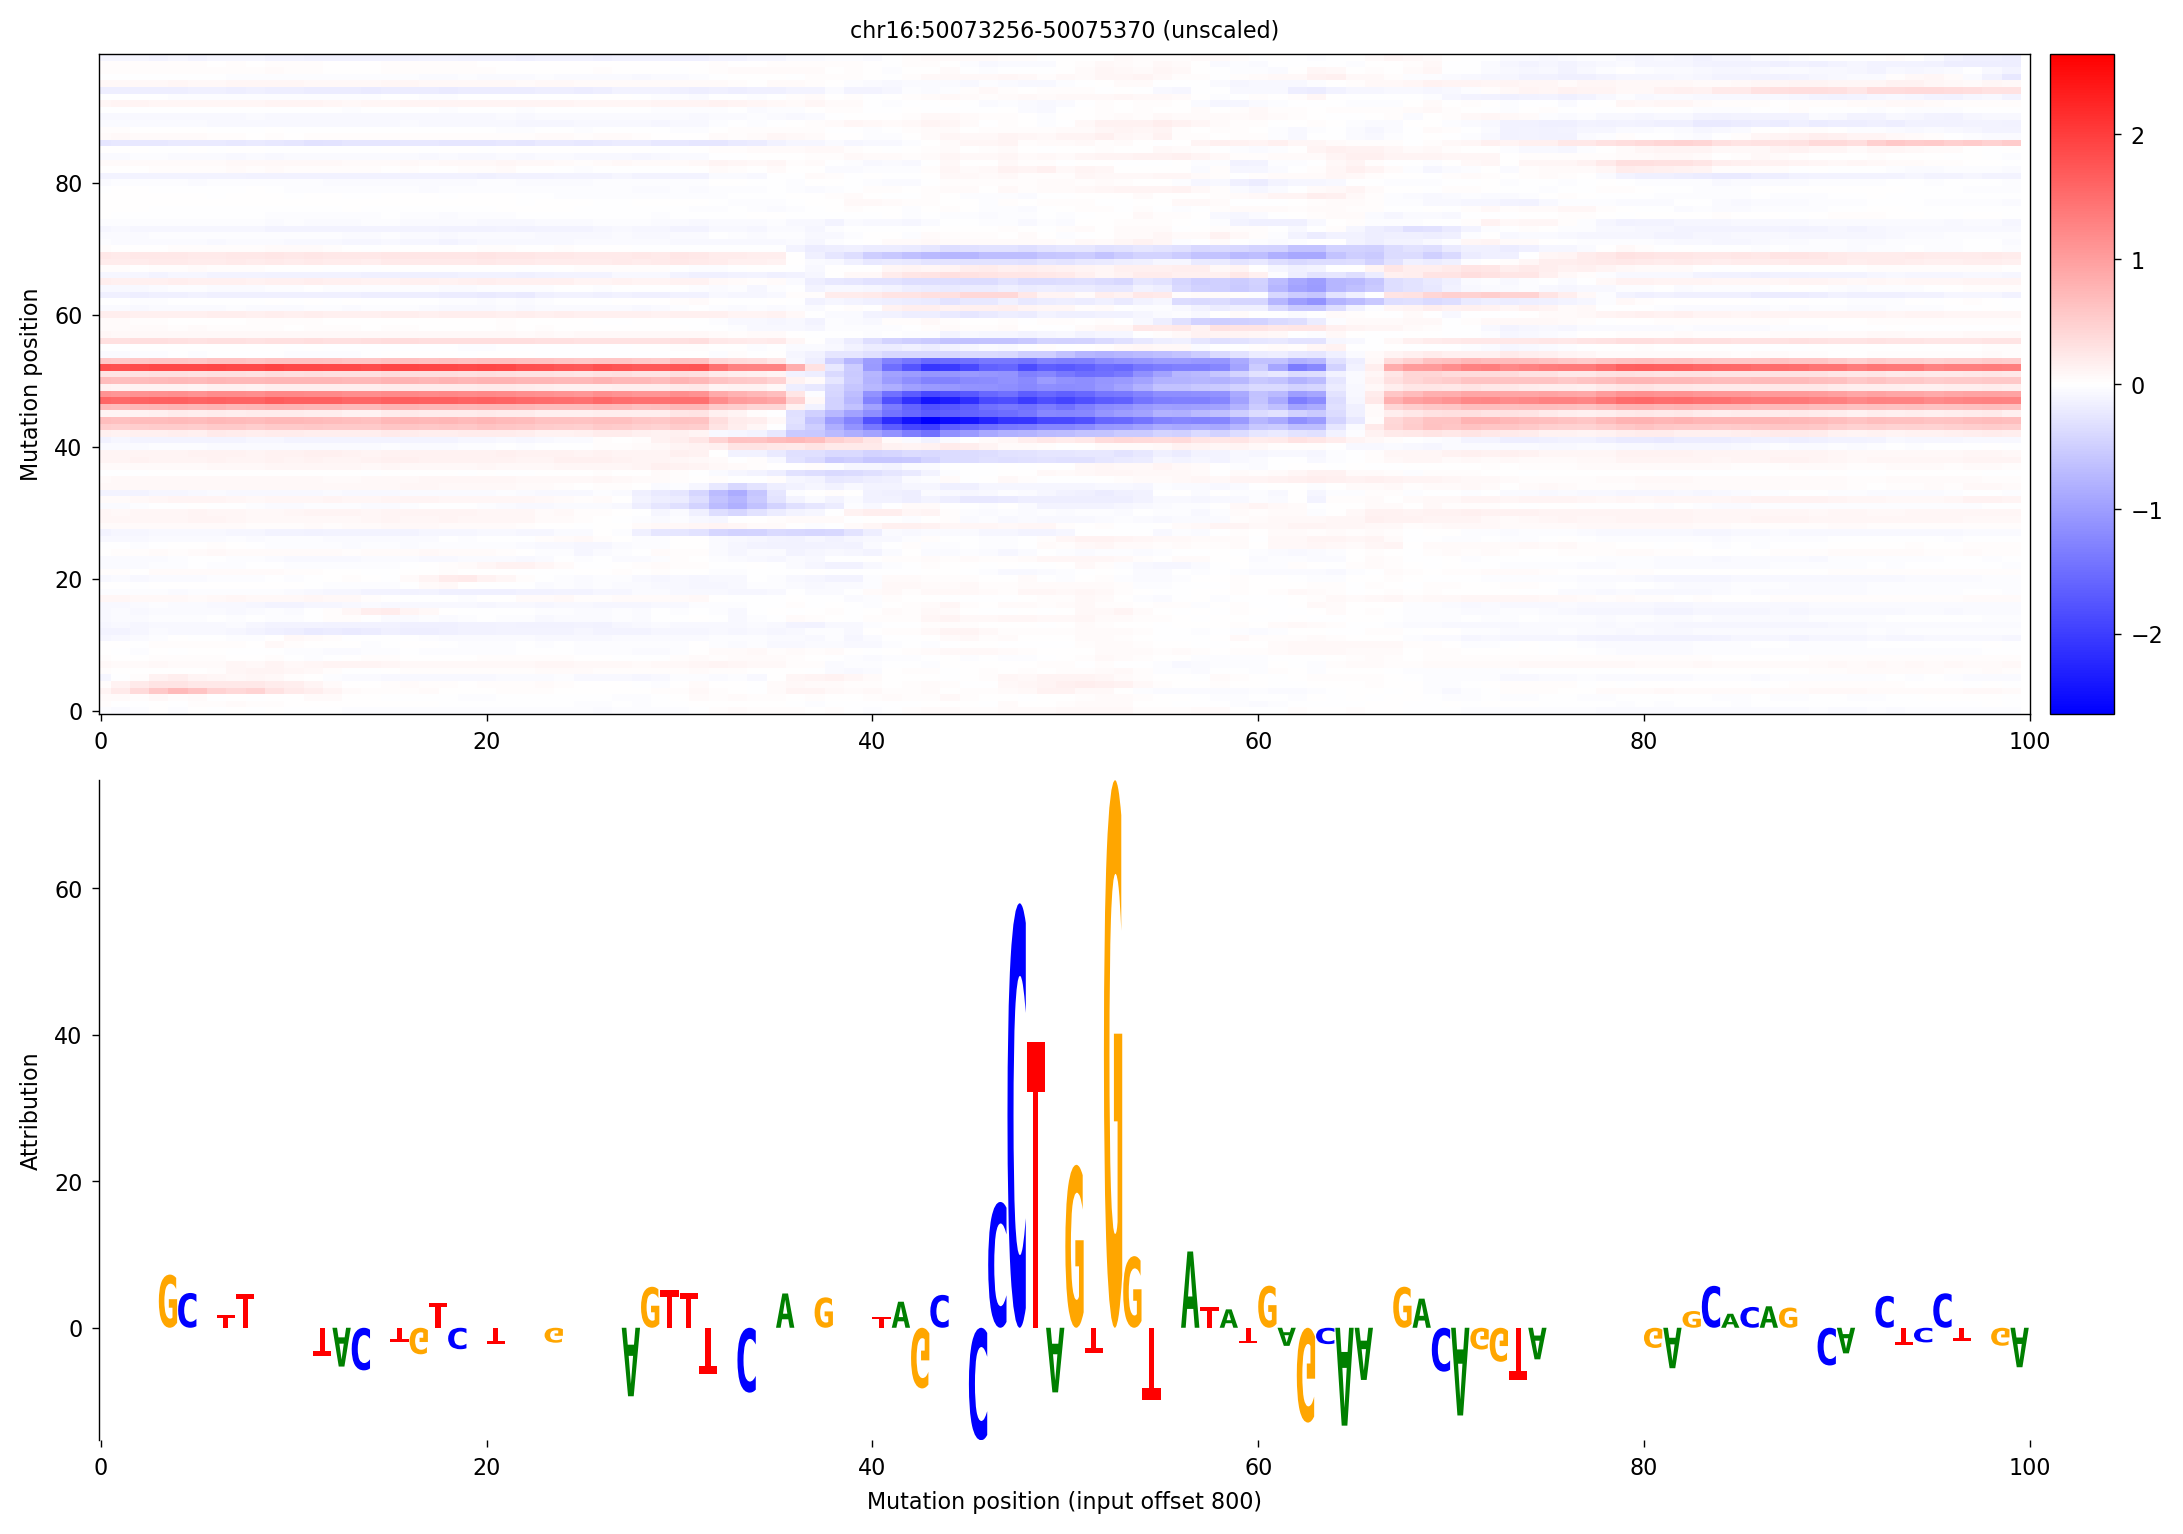

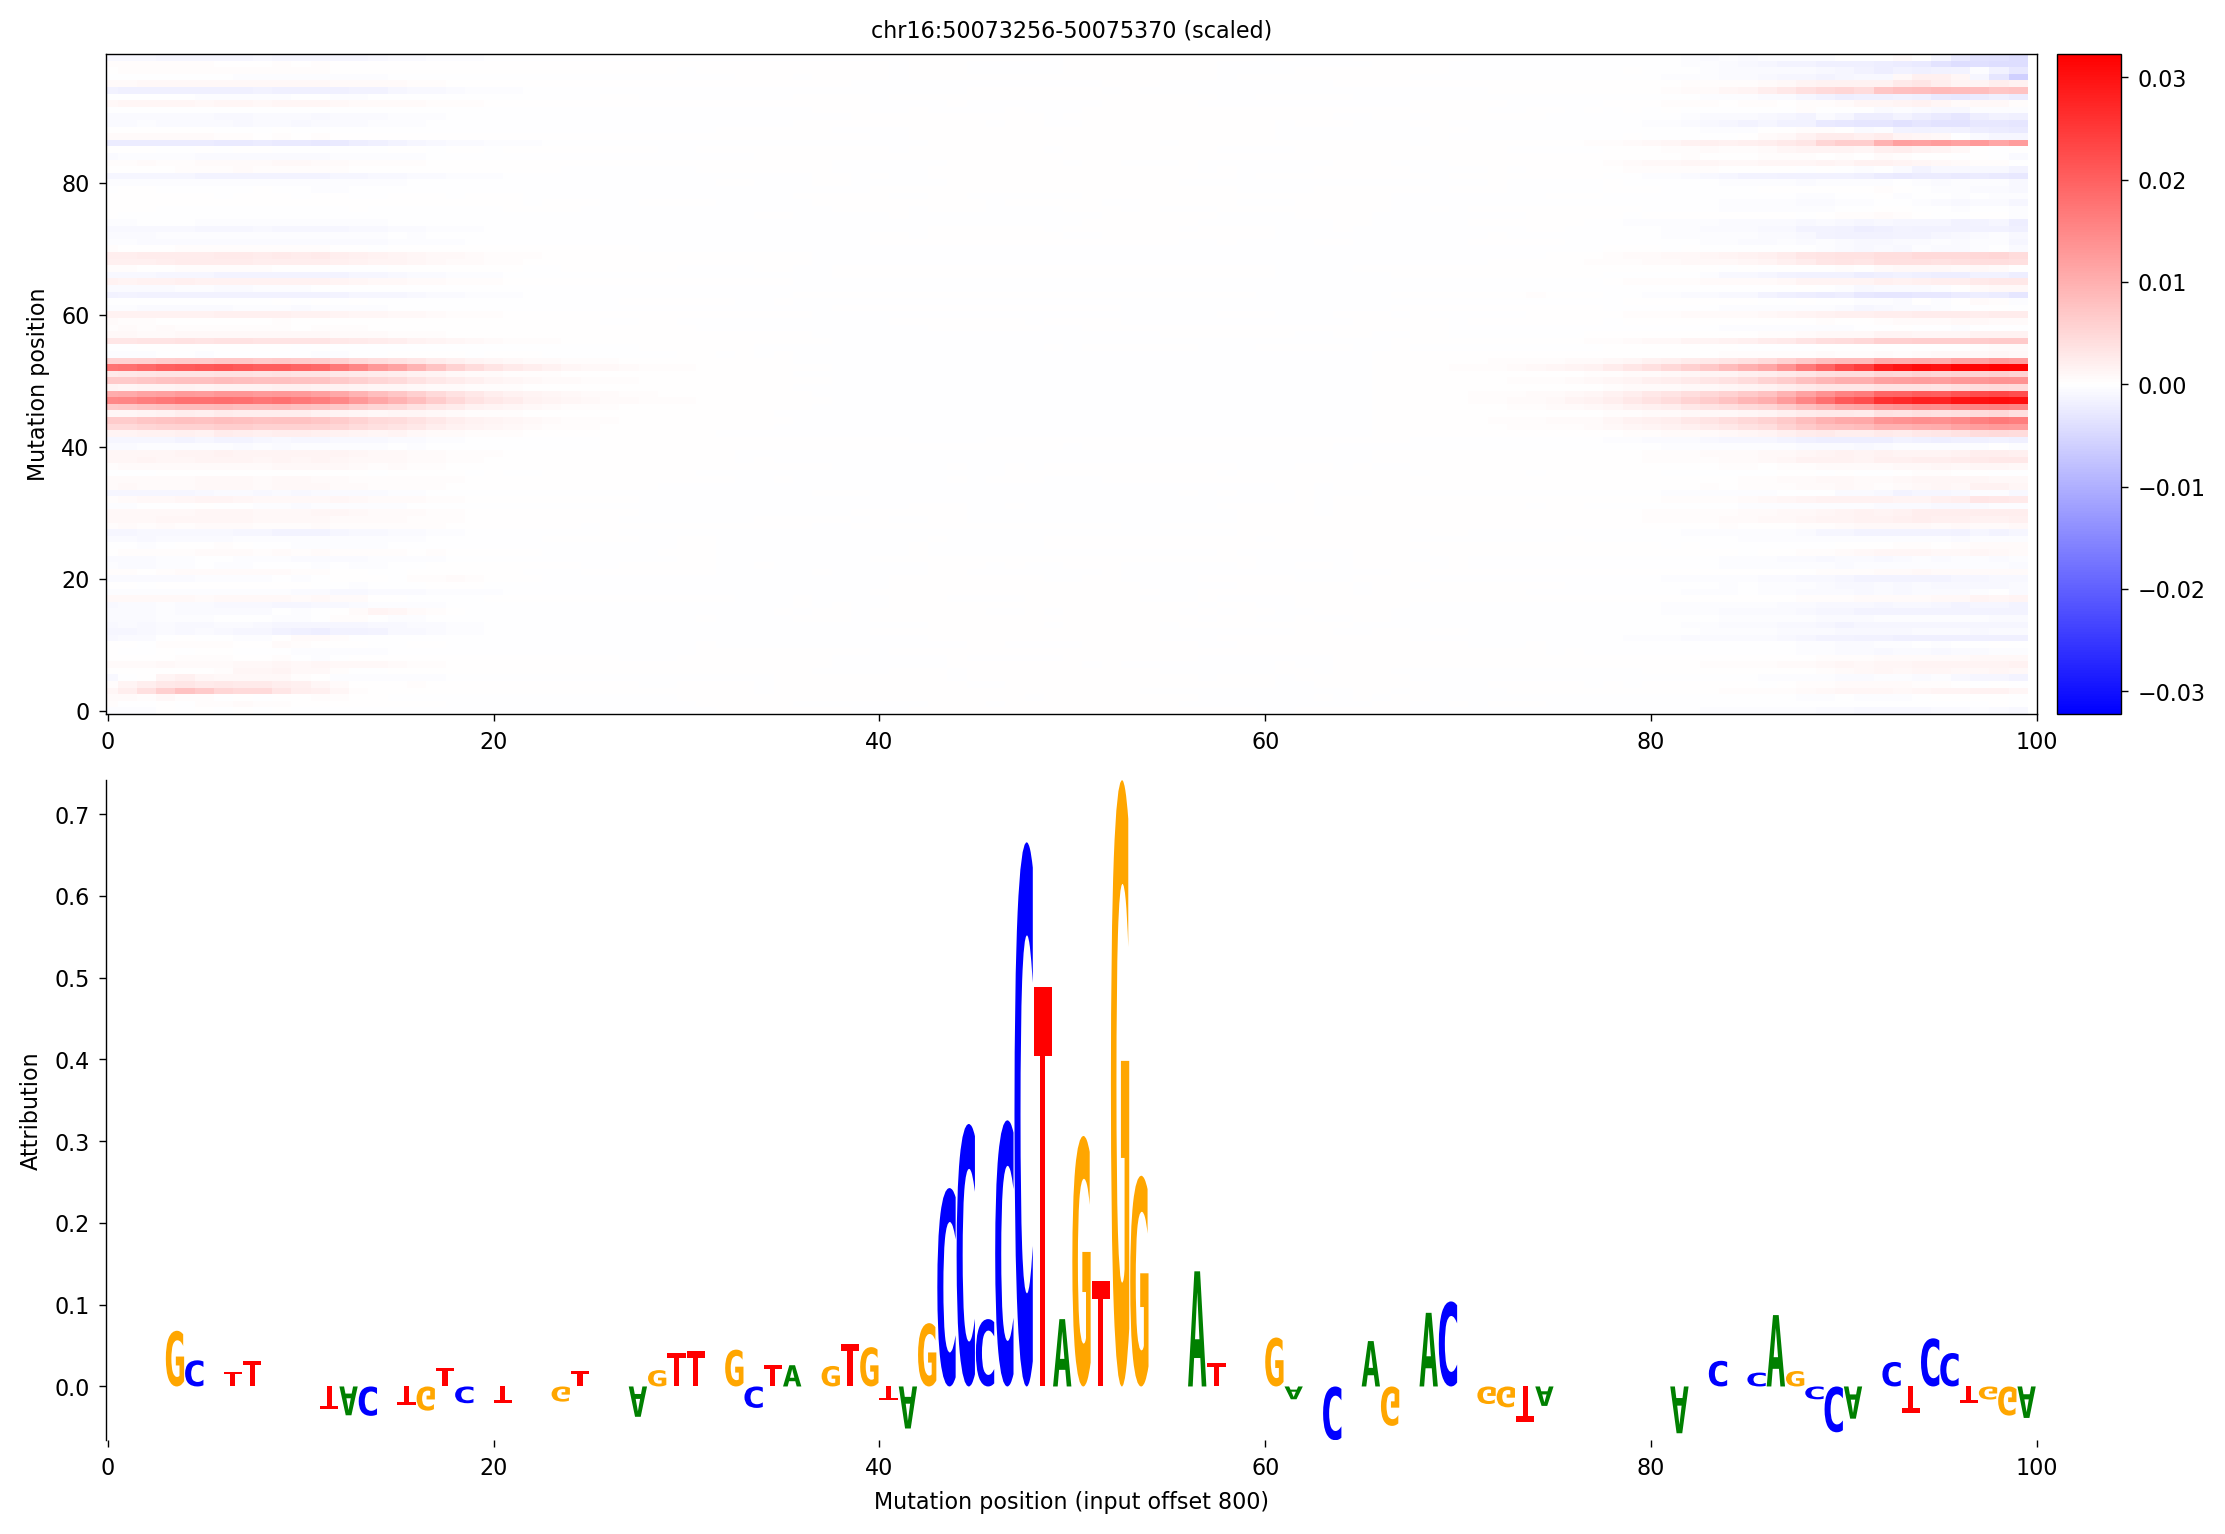

In [6]:
profile = profile_ism(model, dna, mutation_start=mutation_start, length=length)
for scaled in (False, True):
    title = f"{region_id} ({'scaled' if scaled else 'unscaled'})"
    figure = plot_profile_ism(profile, title, scaled=scaled)
    plt.show()

The motif again stands out, as a driver of accessibility on average. Only the per-read view
separates the reads in which the factor is bound from those in which it is not.

## Using your own data

PRISM takes any read and DNA in the model's input coordinates: `dna` holds 2048 bases
(0-3 for A, C, G, T) and `read` holds one call per base (1, 0, or -1 for no call), of which
the model scores the central 1024. The example region was extracted from the training data
like this:

```python
from smf_net.data import SparseDataModuleConfig, SparseSMFDataModule

data = SparseSMFDataModule(
    SparseDataModuleConfig(
        fasta_path="mm10.fa",
        h5_path="ONT_mESC_acRegions.h5",
        h5_region_length=2114,
        train_chrm=["chr19"],
        val_chrm=["chr16"],
        test_chrm=["chr1"],
    )
)
data.setup("validate")
dataset = data.val_dataset
region = dataset.get_region(dataset.regions.index("chr16:50073256-50075370"))
np.savez_compressed(
    "ont_mesc_chr16_50073256-50075370.npz",
    region_id=region.region_id,
    dna=region.dna.numpy(),
    positions=region.positions.numpy(),
    smf=region.smf.numpy(),
)
```

`smf_net.evaluation.prism` also has `prism_log_ratio`, which compares two reads directly, and
`score_read_mutations`, which scores a read under any set of mutated sequences.